# Laboratório: Análise de Dados com Pandas — Aluguéis no Rio de Janeiro (2020) 🏙️

**Disciplina:** Laboratório de Programação — Ciência da Computação (UFPI)  
**Prof.:** Armando Soares Sousa — Departamento de Computação

---

## 🎯 Objetivos da atividade

Ao final deste laboratório você será capaz de:

1. **Ler** arquivos de dados nos formatos CSV e Excel com o Pandas.
2. **Explorar** uma tabela: tamanho, colunas, tipos, estatísticas.
3. **Identificar e tratar valores ausentes** (`NaN`).
4. **Detectar dados suspeitos** (*outliers*) e entender como eles distorcem uma análise.
5. **Filtrar**, **ordenar** e **agrupar** dados para responder perguntas.
6. Calcular e interpretar a **correlação** entre variáveis.
7. **Visualizar** resultados com gráficos simples.

## 🗺️ Roteiro sugerido (≈ 100 minutos)

| Parte | Conteúdo | Tempo |
|---|---|---|
| 0 | Preparação do ambiente | 5 min |
| 1 | Lendo e conhecendo os dados | 15 min |
| 2 | Valores ausentes (`NaN`) | 10 min |
| 3 | Dados suspeitos e limpeza | 15 min |
| 4 | Perguntas guiadas | 35 min |
| 5 | Exercícios para você resolver | 20 min |

## 🧭 Como usar este notebook

- Execute as células **na ordem**, de cima para baixo (atalho: `Shift + Enter`).
- **Leia o texto antes de executar** cada célula e tente **prever o resultado**.
- Os blocos **🤔 Pare e pense** são para discussão com a turma.
- Os blocos **✍️ Sua vez** têm células vazias para você escrever código.
- Deu erro? Leia a mensagem com calma: a última linha costuma dizer exatamente o que aconteceu.

---
# Parte 0 — Preparação do ambiente

| Biblioteca | Apelido | Para que serve |
|---|---|---|
| `pandas` | `pd` | manipular tabelas de dados |
| `matplotlib.pyplot` | `plt` | desenhar gráficos |
| `seaborn` | `sns` | gráficos estatísticos (usaremos para o "mapa de calor") |

> 💡 Os apelidos `pd`, `plt` e `sns` são **convenções** da comunidade. Você os encontrará em praticamente todo material sobre o assunto.

In [2]:
!pip install seaborn


[notice] A new release of pip is available: 25.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versão do Pandas:", pd.__version__)

Versão do Pandas: 2.2.3


Vamos configurar a exibição de números decimais com separador de milhar e 2 casas:

In [4]:
pd.set_option("display.float_format", "{:,.2f}".format)

---
# Parte 1 — Lendo e conhecendo os dados

## 1.1 O conjunto de dados

Vamos analisar cerca de **20 mil anúncios de imóveis para aluguel** na cidade do Rio de Janeiro, coletados em 2020.
Cada **linha** da tabela é **um anúncio** (um imóvel).

O mapa abaixo ajuda a localizar alguns bairros que vão aparecer na análise. Repare na região próxima às praias (Leblon, Ipanema, Copacabana) — a chamada **Zona Sul** — e na Barra da Tijuca, a oeste.

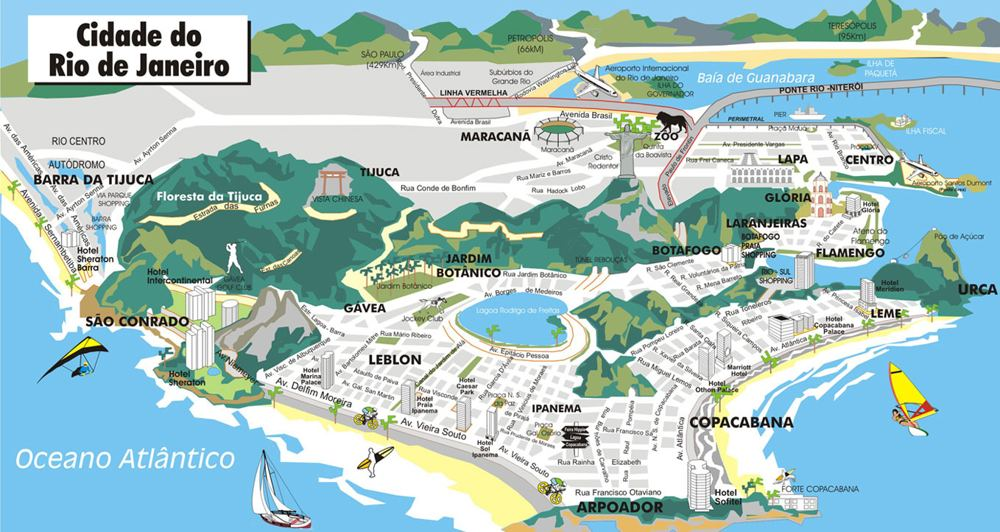

## 1.2 O formato CSV

**CSV** (*Comma-Separated Values*) é um arquivo de texto em que cada linha é um registro e os valores são separados por um caractere separador.
Apesar do nome ("separado por vírgula"), no Brasil é muito comum usar **ponto e vírgula** (`;`), porque a vírgula já é usada nos números decimais.

As primeiras linhas do nosso arquivo são assim:

```
Tipo;Bairro;Quartos;Vagas;Suites;Area;Valor;Condominio;IPTU;Valor m2;Tipo Agregado
Apartamento;Centro;1;0;0;15;800.0;390.0;20.0;53.33;Apartamento
Apartamento;Higienópolis;1;0;0;48;800.0;230.0;0.0;16.67;Apartamento
```

Por isso, ao ler o arquivo, precisamos informar o separador com `sep=";"`.

📖 Documentação: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

> 🤔 **Pare e pense:** o que aconteceria se esquecêssemos o `sep=";"`? Experimente na célula abaixo e observe quantas colunas o Pandas encontra.

> 💡 **Alternativa (Google Colab / Linux):** baixar o arquivo com um comando do terminal e depois ler localmente:
> ```
> !wget https://raw.githubusercontent.com/armandossrecife/lp20232/main/aluguel.csv
> df_aluguel = pd.read_csv("aluguel.csv", sep=";")
> ```

## 1.3 Primeiro contato

In [6]:
!wget https://raw.githubusercontent.com/armandossrecife/lp20232/main/aluguel.csv

--2026-10-22 12:37:43--  https://raw.githubusercontent.com/armandossrecife/lp20232/main/aluguel.csv
Resolvendo raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8001::154, 2606:50c0:8002::154, ...
Conectando-se a raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... conectado.
A requisição HTTP foi enviada, aguardando resposta... 200 OK
Tamanho: 1396187 (1,3M) [text/plain]
Salvando em: “aluguel.csv”

aluguel.csv         100%[===================>]   1,33M  6,94MB/s    em 0,2s    

2026-10-22 12:37:43 (6,94 MB/s) - “aluguel.csv” salvo [1396187/1396187]



In [7]:
df_aluguel = pd.read_csv("aluguel.csv", sep=";")

In [8]:
print(f"A tabela tem {df_aluguel.shape[0]:,} linhas (anúncios) e {df_aluguel.shape[1]} colunas.")

A tabela tem 19,831 linhas (anúncios) e 11 colunas.


In [9]:
df_aluguel.head()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU,Valor m2,Tipo Agregado
0,Apartamento,Centro,1,0,0,15,800.00,390.00,20.00,53.33,Apartamento
1,Apartamento,Higienópolis,1,0,0,48,800.00,230.00,0.00,16.67,Apartamento
2,Apartamento,Cachambi,2,0,0,50,"1,300.00",301.00,17.00,26.00,Apartamento
3,Apartamento,Grajaú,2,1,0,70,"1,500.00",642.00,74.00,21.43,Apartamento
4,Apartamento,Lins de Vasconcelos,3,1,1,90,"1,500.00",455.00,14.00,16.67,Apartamento


In [10]:
df_aluguel.tail()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU,Valor m2,Tipo Agregado
19826,Quitinete,Glória,1,0,0,10,400.00,107.00,10.00,40.00,Apartamento
19827,Quitinete,Flamengo,1,0,0,23,900.00,605.00,0.00,39.13,Apartamento
19828,Quitinete,Centro,1,0,0,24,"1,100.00",323.00,0.00,45.83,Apartamento
19829,Quitinete,Copacabana,1,0,0,22,"1,500.00",286.00,200.00,68.18,Apartamento
19830,Quitinete,Centro,0,0,0,27,800.00,350.00,25.00,29.63,Apartamento


## 1.4 Dicionário de dados

| Coluna | Significado | Exemplo |
|---|---|---|
| `Tipo` | tipo do imóvel | `Apartamento`, `Casa`, `Quitinete` |
| `Bairro` | bairro do Rio de Janeiro | `Copacabana` |
| `Quartos` | número de quartos | `2` |
| `Vagas` | vagas de garagem | `1` |
| `Suites` | quartos com banheiro próprio | `1` |
| `Area` | área do imóvel em m² | `70` |
| `Valor` | valor do **aluguel** mensal em R$ | `1500.0` |
| `Condominio` | taxa de condomínio mensal em R$ | `642.0` |
| `IPTU` | imposto predial (valor mensal) em R$ | `74.0` |
| `Valor m2` | valor do aluguel dividido pela área (R$/m²) | `21.43` |
| `Tipo Agregado` | agrupamento do tipo: `Apartamento` ou `Casa` | `Apartamento` |

Vamos **conferir** se a coluna `Valor m2` é mesmo `Valor ÷ Area`. Operações entre colunas são feitas **linha a linha**, automaticamente:

In [11]:
calculado = df_aluguel["Valor"] / df_aluguel["Area"]
diferenca = (calculado - df_aluguel["Valor m2"]).abs()

print("Maior diferença encontrada:", diferenca.max())

Maior diferença encontrada: 0.005000000000002558


A maior diferença é de menos de 1 centavo (arredondamento). ✅ Confirmado!

> 💡 Conferir se os dados "fazem sentido" é um hábito importante de quem analisa dados.

## 1.5 Tipos de dados e estatísticas

In [12]:
df_aluguel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19831 entries, 0 to 19830
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Tipo           19831 non-null  object 
 1   Bairro         19831 non-null  object 
 2   Quartos        19831 non-null  int64  
 3   Vagas          19831 non-null  int64  
 4   Suites         19831 non-null  int64  
 5   Area           19831 non-null  int64  
 6   Valor          19831 non-null  float64
 7   Condominio     19831 non-null  float64
 8   IPTU           19831 non-null  float64
 9   Valor m2       19831 non-null  float64
 10  Tipo Agregado  19831 non-null  object 
dtypes: float64(4), int64(4), object(3)
memory usage: 1.7+ MB


Na saída de `info()`:
- `int64` = números inteiros; `float64` = números decimais; `object`/`str` = texto;
- `Non-Null Count` = quantos valores **não estão vazios** em cada coluna.

In [13]:
df_aluguel.describe()

,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU,Valor m2
count,"19,831.00","19,831.00","19,831.00","19,831.00","19,831.00","19,831.00","19,831.00","19,831.00"
mean,2.41,1.20,0.82,120.27,"3,465.40","1,386.19",433.98,31.11
std,1.03,13.96,1.03,126.60,"3,291.36","46,692.23","3,698.12",15.07
min,0.00,0.00,0.00,10.00,100.00,0.00,0.00,2.78
25%,2.00,0.00,0.00,62.00,"1,500.00",500.00,0.00,20.12
50%,2.00,1.00,1.00,85.00,"2,500.00",800.00,100.00,28.16
75%,3.00,2.00,1.00,130.00,"4,300.00","1,336.00",294.00,39.00
max,14.00,"1,960.00",14.00,"3,000.00","32,000.00","6,552,570.00","450,625.00",471.80


| Linha do `describe()` | Significado |
|---|---|
| `count` | quantidade de valores |
| `mean` | média |
| `std` | desvio padrão (o quanto os valores se espalham) |
| `min` / `max` | menor e maior valor |
| `25%`, `50%`, `75%` | quartis — o `50%` é a **mediana** (o valor "do meio") |

> 🤔 **Pare e pense:** olhe com atenção a linha `max`.
> - Existe um imóvel com **1.960 vagas de garagem**?!
> - Um condomínio de mais de **R$ 6 milhões por mês**?!
>
> Guarde essas perguntas — vamos investigar na Parte 3.

---
# Parte 2 — Valores ausentes (`NaN`)

Em dados reais é muito comum faltar informação: o anunciante não preencheu o condomínio, o IPTU etc.
No Pandas, um valor ausente aparece como **`NaN`** (*Not a Number*).

## 2.1 Nosso CSV tem valores ausentes?

`isna()` devolve `True` onde o valor está ausente. Somando por coluna, temos a quantidade de ausentes:

In [14]:
df_aluguel.isna().sum()

Tipo             0
Bairro           0
Quartos          0
Vagas            0
Suites           0
Area             0
Valor            0
Condominio       0
IPTU             0
Valor m2         0
Tipo Agregado    0
dtype: int64

Nenhum valor ausente — este CSV já foi **tratado** antes de ser publicado.

## 2.2 Praticando com uma amostra "suja" (arquivo Excel)

Para praticar, vamos usar uma pequena amostra **ainda não tratada**, em formato **Excel** (`.xlsx`).
O Pandas lê planilhas Excel com `pd.read_excel`.

📖 https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html

In [15]:
URL_XLSX = "https://raw.githubusercontent.com/armandossrecife/lp20232/main/aluguel.xlsx"

!wget {URL_XLSX}

--2026-10-22 12:38:43--  https://raw.githubusercontent.com/armandossrecife/lp20232/main/aluguel.xlsx
Resolvendo raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8001::154, 2606:50c0:8002::154, ...
Conectando-se a raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... conectado.
A requisição HTTP foi enviada, aguardando resposta... 200 OK
Tamanho: 10504 (10K) [application/octet-stream]
Salvando em: “aluguel.xlsx”

aluguel.xlsx        100%[===================>]  10,26K  --.-KB/s    em 0s      

2026-10-22 12:38:44 (79,5 MB/s) - “aluguel.xlsx” salvo [10504/10504]



In [17]:
df_amostra = pd.read_excel("aluguel.xlsx")
df_amostra

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700,500.00,60.00
1,Casa,Jardim Botânico,2,0,1,100,7000,NaN,NaN
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200,"4,020.00","1,111.00"
3,Apartamento,Centro,1,0,0,15,800,390.00,20.00
4,Apartamento,Higienópolis,1,0,0,48,800,230.00,NaN
5,Apartamento,Vista Alegre,3,1,0,70,1200,NaN,NaN
6,Apartamento,Cachambi,2,0,0,50,1300,301.00,17.00
7,Casa de Condomínio,Barra da Tijuca,5,4,5,750,22000,NaN,NaN
8,Casa de Condomínio,Ramos,2,2,0,65,1000,NaN,NaN
9,Conjunto Comercial/Sala,Centro,0,3,0,695,35000,"19,193.00","3,030.00"


In [18]:
df_amostra.isna().sum()

Tipo          0
Bairro        0
Quartos       0
Vagas         0
Suites        0
Area          0
Valor         0
Condominio    4
IPTU          5
dtype: int64

Agora sim: `Condominio` e `IPTU` têm valores ausentes. Temos basicamente duas estratégias:

| Estratégia | Comando | Quando faz sentido |
|---|---|---|
| **Remover** as linhas com ausentes | `df.dropna()` | quando o valor ausente é essencial e faltam poucos registros |
| **Preencher** os ausentes | `df.fillna(valor)` | quando existe um valor razoável para substituir |

### Estratégia 1 — remover

In [19]:
df_sem_ausentes = df_amostra.dropna()
print("Linhas antes:", len(df_amostra), "| Linhas depois:", len(df_sem_ausentes))
df_sem_ausentes

Linhas antes: 10 | Linhas depois: 5


,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700,500.00,60.00
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200,"4,020.00","1,111.00"
3,Apartamento,Centro,1,0,0,15,800,390.00,20.00
6,Apartamento,Cachambi,2,0,0,50,1300,301.00,17.00
9,Conjunto Comercial/Sala,Centro,0,3,0,695,35000,"19,193.00","3,030.00"


Perdemos metade da amostra! Remover nem sempre é a melhor ideia.

Também podemos remover apenas as linhas em que **uma coluna específica** está vazia, com o parâmetro `subset`:

In [20]:
df_amostra.dropna(subset=["Condominio"])

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700,500.00,60.00
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200,"4,020.00","1,111.00"
3,Apartamento,Centro,1,0,0,15,800,390.00,20.00
4,Apartamento,Higienópolis,1,0,0,48,800,230.00,NaN
6,Apartamento,Cachambi,2,0,0,50,1300,301.00,17.00
9,Conjunto Comercial/Sala,Centro,0,3,0,695,35000,"19,193.00","3,030.00"


### Estratégia 2 — preencher

Uma casa fora de condomínio realmente **não paga** taxa de condomínio. Nesse caso, faz sentido preencher o ausente com `0`:

In [21]:
df_preenchido = df_amostra.fillna({"Condominio": 0, "IPTU": 0})
df_preenchido

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
0,Quitinete,Copacabana,1,0,0,40,1700,500.00,60.00
1,Casa,Jardim Botânico,2,0,1,100,7000,0.00,0.00
2,Conjunto Comercial/Sala,Barra da Tijuca,0,4,0,150,5200,"4,020.00","1,111.00"
3,Apartamento,Centro,1,0,0,15,800,390.00,20.00
4,Apartamento,Higienópolis,1,0,0,48,800,230.00,0.00
5,Apartamento,Vista Alegre,3,1,0,70,1200,0.00,0.00
6,Apartamento,Cachambi,2,0,0,50,1300,301.00,17.00
7,Casa de Condomínio,Barra da Tijuca,5,4,5,750,22000,0.00,0.00
8,Casa de Condomínio,Ramos,2,2,0,65,1000,0.00,0.00
9,Conjunto Comercial/Sala,Centro,0,3,0,695,35000,"19,193.00","3,030.00"


> 💡 Passamos um **dicionário** para `fillna` dizendo qual valor usar em cada coluna.

> 🤔 **Pare e pense:** a amostra contém o tipo `Conjunto Comercial/Sala`. Esse tipo de imóvel deveria estar em uma análise de **aluguel residencial**? Ele aparece no CSV completo? (Você vai verificar isso nos exercícios.)

### Uma nota sobre `axis`

Vários métodos do Pandas têm o parâmetro `axis`:

- `axis=0` → opera sobre as **linhas** (índice);
- `axis=1` → opera sobre as **colunas**.

Exemplo: `df.drop(columns=["IPTU"])` é equivalente a `df.drop("IPTU", axis=1)`.  
Usar `columns=` ou `index=` deixa o código mais legível, e é o que faremos neste notebook.

---
# Parte 3 — Dados suspeitos e limpeza

## 3.1 Escolhendo as colunas de interesse

Nosso foco é o **valor do aluguel**. Vamos trabalhar só com as colunas que descrevem o imóvel e o aluguel:

In [22]:
colunas = ["Tipo", "Bairro", "Quartos", "Vagas", "Suites", "Area", "Valor", "Valor m2"]

df = df_aluguel[colunas].copy()
df.head()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
0,Apartamento,Centro,1,0,0,15,800.00,53.33
1,Apartamento,Higienópolis,1,0,0,48,800.00,16.67
2,Apartamento,Cachambi,2,0,0,50,"1,300.00",26.00
3,Apartamento,Grajaú,2,1,0,70,"1,500.00",21.43
4,Apartamento,Lins de Vasconcelos,3,1,1,90,"1,500.00",16.67


> 💡 O `.copy()` cria uma **cópia independente**. Assim, alterações em `df` não afetam `df_aluguel` (e o Pandas não emite avisos).

## 3.2 Investigando as vagas de garagem 🕵️

Vamos ver os imóveis com **mais de 10 vagas**:

In [23]:
df.query("Vagas > 10").sort_values("Vagas", ascending=False)

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
14954,Apartamento,Copacabana,2,1960,0,80,"1,600.00",20.00
18098,Casa de Condomínio,Joá,6,35,4,1100,"22,000.00",20.00
17784,Casa,Recreio dos Bandeirantes,3,30,0,600,"8,000.00",13.33
17261,Casa,Vila Valqueire,5,20,0,460,"16,000.00",34.78
17314,Casa,Jacarepaguá,8,20,7,2000,"15,000.00",7.50
17397,Casa,Recreio dos Bandeirantes,3,20,1,100,"8,000.00",80.00
18536,Casa de Condomínio,Barra da Tijuca,4,16,4,400,"10,000.00",25.00
5016,Apartamento,Flamengo,1,11,0,60,"2,100.00",35.00


Algumas casas grandes com 20 ou 30 vagas são até possíveis... mas um **apartamento de 80 m² em Copacabana com 1.960 vagas** é claramente um **erro de digitação** no anúncio (talvez o ano de construção do prédio? 😄).

Valores muito distantes do restante são chamados de **outliers** (valores atípicos).

## 3.3 Como um único erro distorce a análise

A **correlação** mede o quanto duas variáveis "andam juntas" (veremos mais detalhes na Pergunta 7). Ela vai de −1 a 1.
Vamos calcular a correlação entre `Vagas` e `Valor` **com** e **sem** esse único anúncio:

In [24]:
corr_com_erro = df["Vagas"].corr(df["Valor"])

df_sem_erro = df[df["Vagas"] != 1960]
corr_sem_erro = df_sem_erro["Vagas"].corr(df_sem_erro["Valor"])

print(f"Correlação Vagas x Valor COM o anúncio errado: {corr_com_erro:.2f}")
print(f"Correlação Vagas x Valor SEM o anúncio errado: {corr_sem_erro:.2f}")

Correlação Vagas x Valor COM o anúncio errado: 0.04
Correlação Vagas x Valor SEM o anúncio errado: 0.54


🚨 **Uma única linha errada, entre quase 20 mil**, faz a correlação cair de cerca de **0,54** para **0,04**!
Sem investigar, concluiríamos (erradamente) que o número de vagas não tem relação com o valor do aluguel.

> 🎓 **Lição importante:** sempre investigue os valores extremos antes de tirar conclusões.

## 3.4 Outro caso suspeito

Qual é o aluguel **mais barato** da tabela?

In [25]:
df.nsmallest(5, "Valor")

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
11120,Apartamento,Leblon,0,0,0,15,100.00,6.67
19147,Quitinete,Copacabana,0,0,0,36,100.00,2.78
4306,Apartamento,Engenho de Dentro,1,0,0,30,300.00,10.00
19150,Quitinete,Jacarepaguá,1,0,0,20,300.00,15.00
19634,Quitinete,Anil,1,0,0,20,300.00,15.00


Um apartamento no **Leblon** (um dos bairros mais caros do Brasil) por **R$ 100,00**? Muito provavelmente outro erro de cadastro.

## 3.5 Criando a tabela limpa

Vamos adotar duas regras simples (e explicáveis!) de limpeza:

1. remover **apartamentos com mais de 10 vagas**;
2. remover aluguéis **abaixo de R$ 300,00**.

In [26]:
suspeito_vagas = (df["Tipo"] == "Apartamento") & (df["Vagas"] > 10)
suspeito_valor = df["Valor"] < 300

df_limpo = df[~(suspeito_vagas | suspeito_valor)].copy()

print("Removidos:", len(df) - len(df_limpo), "anúncios")
print("Restaram: ", len(df_limpo), "anúncios")

Removidos: 4 anúncios
Restaram:  19827 anúncios


> 💡 Lembrete dos operadores de máscara: `&` = **E**, `|` = **OU**, `~` = **NÃO**. Cada condição fica entre parênteses.

> 🤔 **Pare e pense:** essas regras são as únicas possíveis? Que outras você criaria? Existe o risco de remover um anúncio **verdadeiro**?

A partir daqui, usaremos sempre `df_limpo`.

---
# Parte 4 — Perguntas guiadas

Para cada pergunta seguimos o ciclo:

> **Pergunta → Ideia (qual comando usar?) → Código → Interpretação**

## Pergunta 1 — Quais tipos de imóveis existem? Quantos de cada?

**Ideia:** `unique()` lista os tipos; `value_counts()` conta cada um.

In [27]:
df_limpo["Tipo"].unique()

array(['Apartamento', 'Casa', 'Casa de Condomínio', 'Casa de Vila',
       'Quitinete'], dtype=object)

In [28]:
contagem_tipos = df_limpo["Tipo"].value_counts()
contagem_tipos

Tipo
Apartamento           16920
Casa de Condomínio      964
Casa                    898
Quitinete               812
Casa de Vila            233
Name: count, dtype: int64

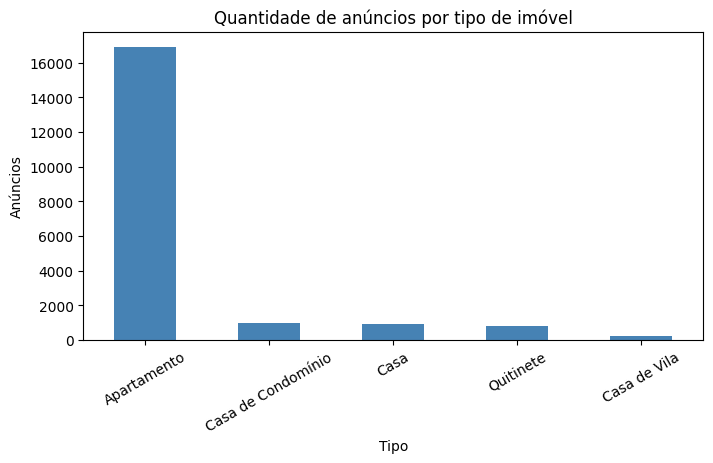

In [29]:
contagem_tipos.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Quantidade de anúncios por tipo de imóvel")
plt.xlabel("Tipo")
plt.ylabel("Anúncios")
plt.xticks(rotation=30)
plt.show()

## Pergunta 2 — Quantos bairros aparecem? Quais têm mais anúncios?

In [30]:
print("Quantidade de bairros:", df_limpo["Bairro"].nunique())

Quantidade de bairros: 151


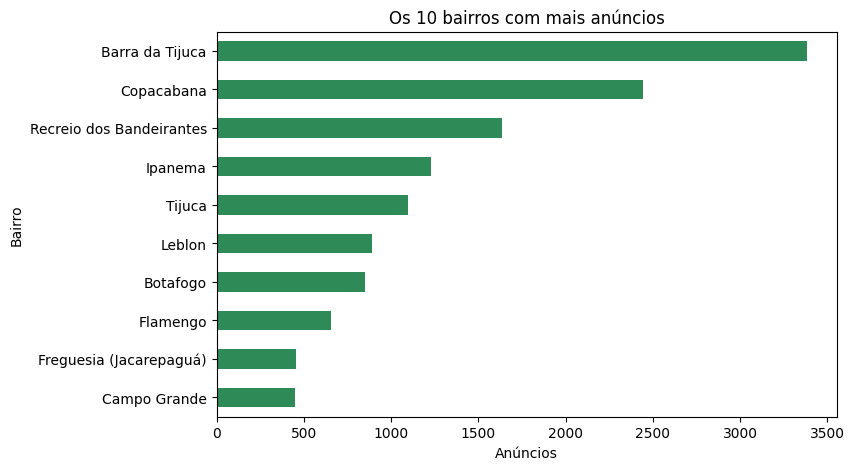

In [31]:
top10_bairros = df_limpo["Bairro"].value_counts().head(10)

top10_bairros.sort_values().plot(kind="barh", figsize=(8, 5), color="seagreen")
plt.title("Os 10 bairros com mais anúncios")
plt.xlabel("Anúncios")
plt.ylabel("Bairro")
plt.show()

## Pergunta 3 — Como se distribuem os valores de aluguel?

In [32]:
print("Menor aluguel:", df_limpo["Valor"].min())
print("Maior aluguel:", df_limpo["Valor"].max())
print("Média:        ", round(df_limpo["Valor"].mean(), 2))
print("Mediana:      ", df_limpo["Valor"].median())

Menor aluguel: 300.0
Maior aluguel: 32000.0
Média:         3465.9
Mediana:       2500.0


Um **histograma** mostra quantos anúncios caem em cada faixa de valor:

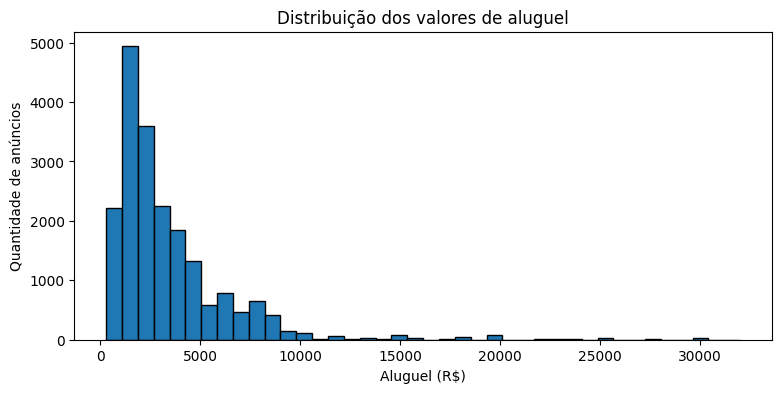

In [33]:
df_limpo["Valor"].plot(kind="hist", bins=40, figsize=(9, 4), edgecolor="black")
plt.title("Distribuição dos valores de aluguel")
plt.xlabel("Aluguel (R$)")
plt.ylabel("Quantidade de anúncios")
plt.show()

### Média × Mediana

- A **média** soma todos os valores e divide pela quantidade — é **puxada** por valores muito altos.
- A **mediana** é o valor **do meio** quando ordenamos os dados — é **resistente** a valores extremos.

O histograma tem uma "cauda" longa à direita (poucos imóveis muito caros). Por isso a **média é maior que a mediana**.
Para descrever o "aluguel típico", a **mediana** é mais representativa.

## Pergunta 4 — E os apartamentos? Qual o mais barato e o mais caro?

**Ideia:** filtrar com `query`; usar `idxmin()`/`idxmax()` para achar a **linha** do menor e do maior valor.

In [34]:
df_apartamentos = df_limpo.query("Tipo == 'Apartamento'")
print(f"Apartamentos: {len(df_apartamentos):,}")
print("Aluguel médio:  ", round(df_apartamentos["Valor"].mean(), 2))
print("Aluguel mediano:", df_apartamentos["Valor"].median())

Apartamentos: 16,920
Aluguel médio:   3141.51
Aluguel mediano: 2500.0


In [35]:
indice_min = df_apartamentos["Valor"].idxmin()   # índice da linha com o menor valor
indice_max = df_apartamentos["Valor"].idxmax()   # índice da linha com o maior valor

df_apartamentos.loc[[indice_min, indice_max]]

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
4306,Apartamento,Engenho de Dentro,1,0,0,30,300.00,10.00
3728,Apartamento,Leblon,3,1,2,150,"9,900.00",66.00


> 💡 `loc[...]` busca linhas pelo **rótulo do índice**. Passando uma **lista** de índices, recebemos várias linhas.

> ⚠️ Pode haver **empate** (vários apartamentos com o mesmo valor mínimo ou máximo). `idxmin`/`idxmax` devolvem só o primeiro. Para ver todos, use: `df_apartamentos.query("Valor == @valor_minimo")`, onde `@` permite usar uma variável Python dentro do `query`.

## Pergunta 5 — Quantos apartamentos há em cada bairro?

`value_counts()` devolve uma **Series**: os bairros ficam no **índice** e as contagens nos **valores**.

In [36]:
apartamentos_por_bairro = df_apartamentos["Bairro"].value_counts()
apartamentos_por_bairro.head()

Bairro
Barra da Tijuca             2839
Copacabana                  2165
Recreio dos Bandeirantes    1458
Ipanema                     1200
Tijuca                      1046
Name: count, dtype: int64

Podemos acessar um bairro específico pelo rótulo, como em um dicionário:

In [37]:
print("Apartamentos em Copacabana:", apartamentos_por_bairro["Copacabana"])

Apartamentos em Copacabana: 2165


E percorrer a Series com um laço `for`, usando `.items()` (que devolve pares *rótulo, valor*):

In [38]:
for bairro, quantidade in apartamentos_por_bairro.head(5).items():
    print(f"{bairro:<28} {quantidade:>5} apartamentos")

Barra da Tijuca               2839 apartamentos
Copacabana                    2165 apartamentos
Recreio dos Bandeirantes      1458 apartamentos
Ipanema                       1200 apartamentos
Tijuca                        1046 apartamentos


### Convertendo a Series em DataFrame

Às vezes é mais prático ter uma tabela com duas colunas. `reset_index()` transforma o índice em uma coluna:

In [39]:
df_qtd_por_bairro = apartamentos_por_bairro.reset_index()
df_qtd_por_bairro.columns = ["bairro", "qtd_apartamentos"]
df_qtd_por_bairro.head()

,bairro,qtd_apartamentos
0,Barra da Tijuca,2839
1,Copacabana,2165
2,Recreio dos Bandeirantes,1458
3,Ipanema,1200
4,Tijuca,1046


## Pergunta 6 — Quais bairros têm o aluguel de apartamento mais caro? E o mais barato?

**Ideia:** `groupby` agrupa os apartamentos por bairro e calcula estatísticas em cada grupo.

O `groupby` funciona em três passos (*dividir → aplicar → combinar*):

1. **Dividir** a tabela em grupos (um grupo para cada bairro);
2. **Aplicar** um cálculo em cada grupo (contar, média, mediana...);
3. **Combinar** os resultados em uma nova tabela.

```
df.groupby("coluna_do_grupo")["coluna_calculada"].agg(["count", "mean", "median"])
```

In [40]:
resumo_bairros = df_apartamentos.groupby("Bairro")["Valor"].agg(["count", "mean", "median"])
resumo_bairros.columns = ["anuncios", "media", "mediana"]
resumo_bairros.head()

,anuncios,media,mediana
Bairro,,,
Abolição,9,994.44,900.00
Alto da Boa Vista,3,"1,483.33","1,600.00"
Anchieta,1,850.00,850.00
Andaraí,91,"1,420.30","1,400.00"
Anil,51,"1,517.45","1,200.00"


Bairros com pouquíssimos anúncios podem gerar conclusões enganosas (a "média" de 2 apartamentos não diz muito).
Vamos considerar só bairros com **pelo menos 30 anúncios**:

In [41]:
bairros_confiaveis = resumo_bairros[resumo_bairros["anuncios"] >= 30]
print("Bairros com pelo menos 30 anúncios:", len(bairros_confiaveis))

bairros_confiaveis.sort_values("mediana", ascending=False).head(10)

Bairros com pelo menos 30 anúncios: 49


,anuncios,media,mediana
Bairro,,,
Ipanema,1200,"5,525.38","5,500.00"
Leblon,861,"5,560.40","5,200.00"
Lagoa,368,"5,034.17","4,800.00"
Península,31,"4,722.58","4,500.00"
Urca,50,"4,321.90","4,250.00"
São Conrado,159,"4,619.86","4,000.00"
Gávea,176,"4,235.76","3,750.00"
Jardim Botânico,188,"3,875.43","3,500.00"
Botafogo,753,"3,412.44","3,200.00"


In [42]:
bairros_confiaveis.sort_values("mediana").head(5)

,anuncios,media,mediana
Bairro,,,
Campo Grande,235,968.09,850.00
Praça Seca,72,954.03,890.00
Madureira,35,988.00,950.00
Lins de Vasconcelos,40,"1,058.75","1,000.00"
Taquara,121,"1,122.78","1,000.00"


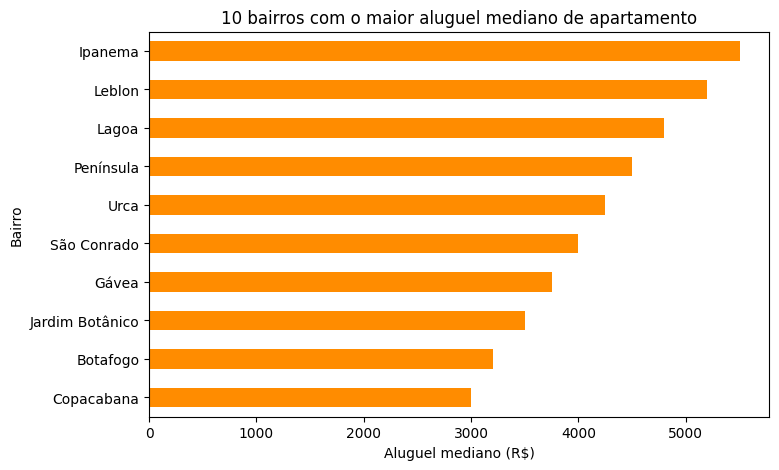

In [43]:
mais_caros = bairros_confiaveis["mediana"].sort_values().tail(10)

mais_caros.plot(kind="barh", figsize=(8, 5), color="darkorange")
plt.title("10 bairros com o maior aluguel mediano de apartamento")
plt.xlabel("Aluguel mediano (R$)")
plt.ylabel("Bairro")
plt.show()

> 🤔 **Pare e pense:** volte ao mapa da Parte 1. Onde ficam os bairros mais caros? Que fatores podem explicar isso (praia, transporte, segurança, oferta de serviços...)?

### Consultando um bairro com uma função

Podemos encapsular a consulta em uma **função**, tratando o caso de um bairro que não existe com uma **exceção**:

In [44]:
def aluguel_mediano(bairro):
    if bairro not in resumo_bairros.index:
        raise ValueError(f"Bairro '{bairro}' não encontrado.")
    return resumo_bairros.loc[bairro, "mediana"]

for b in ["Leblon", "Copacabana", "Atlântida"]:
    try:
        print(f"{b}: R$ {aluguel_mediano(b):,.2f}")
    except ValueError as erro:
        print(erro)

Leblon: R$ 5,200.00
Copacabana: R$ 3,000.00
Bairro 'Atlântida' não encontrado.


> 💡 Também poderíamos pedir o bairro ao usuário com `bairro = input("Qual o bairro? ")`.

## Pergunta 7 — Que características do imóvel mais se relacionam com o valor do aluguel?

**Ideia:** calcular a **correlação de Pearson** entre as colunas numéricas com `corr()`.

| Valor do coeficiente (positivo ou negativo) | Interpretação |
|---|---|
| 0,9 a 1,0 | correlação muito forte |
| 0,7 a 0,9 | forte |
| 0,5 a 0,7 | moderada |
| 0,3 a 0,5 | fraca |
| 0,0 a 0,3 | desprezível |

- **Positiva:** quando uma aumenta, a outra tende a aumentar.
- **Negativa:** quando uma aumenta, a outra tende a diminuir.

📖 https://pt.wikipedia.org/wiki/Coeficiente_de_correlação_de_Pearson

In [45]:
colunas_numericas = ["Quartos", "Vagas", "Suites", "Area", "Valor"]

correlacao = df_limpo[colunas_numericas].corr()
correlacao

,Quartos,Vagas,Suites,Area,Valor
Quartos,1.00,0.57,0.62,0.67,0.62
Vagas,0.57,1.00,0.60,0.62,0.54
Suites,0.62,0.60,1.00,0.66,0.64
Area,0.67,0.62,0.66,1.00,0.80
Valor,0.62,0.54,0.64,0.80,1.00


Um **mapa de calor** (*heatmap*) facilita a leitura: cores mais escuras indicam correlação mais forte.

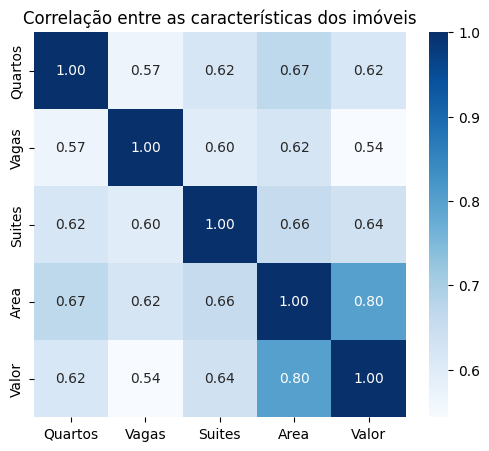

In [46]:
plt.figure(figsize=(6, 5))
sns.heatmap(correlacao, cmap="Blues", annot=True, fmt=".2f")
plt.title("Correlação entre as características dos imóveis")
plt.show()

A **área** é a característica com maior correlação com o valor (≈ 0,80, forte). Vamos visualizar essa relação com um **gráfico de dispersão** (cada ponto é um anúncio):

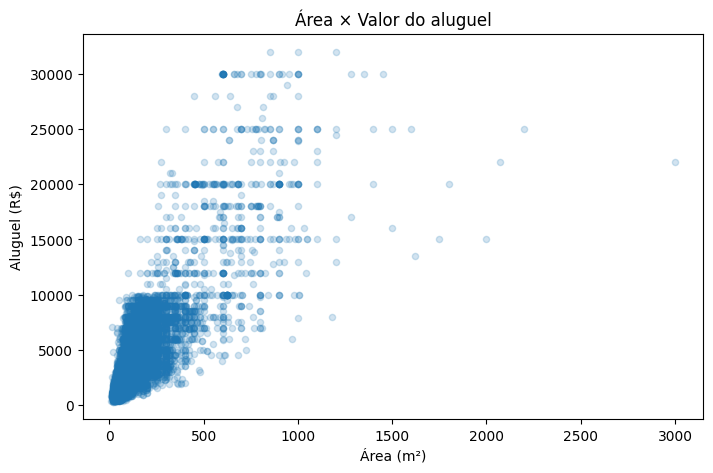

In [47]:
df_limpo.plot(kind="scatter", x="Area", y="Valor", alpha=0.2, figsize=(8, 5))
plt.title("Área × Valor do aluguel")
plt.xlabel("Área (m²)")
plt.ylabel("Aluguel (R$)")
plt.show()

> 🤔 **Pare e pense:**
> - Na tabela original (Parte 3.3), a correlação entre `Vagas` e `Valor` era 0,04. Por que agora ela é bem maior?
> - Correlação significa **causa**? Ter mais vagas *causa* um aluguel mais caro, ou imóveis maiores e mais caros *costumam* ter mais vagas?

## Pergunta 8 — Comparando bairros de forma mais justa: o valor do m²

Um bairro pode ter aluguel mediano alto simplesmente porque seus imóveis são **maiores**.
O **valor por m²** "desconta" o tamanho e permite comparar melhor.

In [48]:
m2_por_bairro = df_apartamentos.groupby("Bairro")["Valor m2"].agg(["count", "median"])
m2_por_bairro = m2_por_bairro[m2_por_bairro["count"] >= 30]

m2_por_bairro.sort_values("median", ascending=False).head(10)

,count,median
Bairro,,
Ipanema,1200,47.62
Leblon,861,47.50
Gávea,176,42.53
Urca,50,40.30
Jardim Botânico,188,39.74
Lagoa,368,39.13
Botafogo,753,38.67
Leme,206,38.08
Humaitá,147,37.88


> 🤔 **Pare e pense:** compare esta lista com a da Pergunta 6.
> - **São Conrado** está entre os 10 maiores aluguéis medianos, mas **não** aparece entre os 10 maiores valores por m². O que isso sugere sobre o tamanho dos apartamentos de lá?
> - Já **Leme** e **Humaitá** aparecem aqui, mas não na Pergunta 6. Por quê?

## Pergunta 9 — Busca personalizada

Quais apartamentos da **Barra da Tijuca**, com **3 quartos**, custam **até R$ 3.000,00**?

Vamos guardar os critérios em **variáveis** e usá-las no `query` com `@`:

In [49]:
bairro_desejado = "Barra da Tijuca"
quartos_desejados = 3
valor_maximo = 3000

resultado = df_apartamentos.query(
    "Bairro == @bairro_desejado and Quartos == @quartos_desejados and Valor <= @valor_maximo"
)

print(f"Encontrados: {len(resultado)} apartamentos")
resultado.head()

Encontrados: 287 apartamentos


,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
19,Apartamento,Barra da Tijuca,3,1,2,70,"1,800.00",25.71
24,Apartamento,Barra da Tijuca,3,1,1,72,"2,350.00",32.64
44,Apartamento,Barra da Tijuca,3,2,1,104,"2,600.00",25.00
51,Apartamento,Barra da Tijuca,3,2,2,85,"2,500.00",29.41
81,Apartamento,Barra da Tijuca,3,2,1,128,"3,000.00",23.44


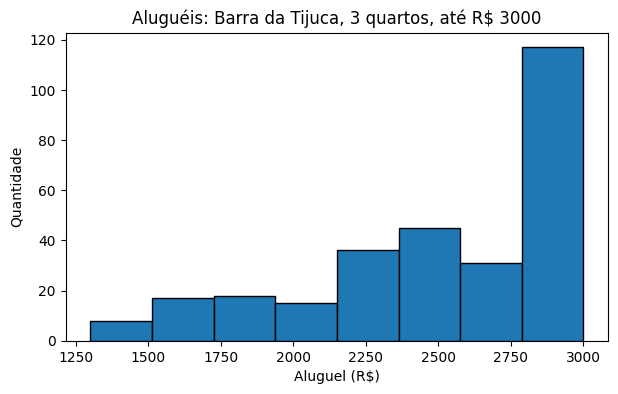

In [50]:
resultado["Valor"].plot(kind="hist", bins=8, figsize=(7, 4), edgecolor="black")
plt.title(f"Aluguéis: {bairro_desejado}, {quartos_desejados} quartos, até R$ {valor_maximo}")
plt.xlabel("Aluguel (R$)")
plt.ylabel("Quantidade")
plt.show()

Refinando a busca: entre esses, quais custam **pelo menos R$ 2.500**, têm **1 vaga** e **1 suíte**?

In [51]:
resultado.query("Valor >= 2500 and Vagas == 1 and Suites == 1").sort_values("Valor")

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Valor m2
167,Apartamento,Barra da Tijuca,3,1,1,105,"2,500.00",23.81
7322,Apartamento,Barra da Tijuca,3,1,1,90,"2,500.00",27.78
11661,Apartamento,Barra da Tijuca,3,1,1,90,"2,500.00",27.78
11834,Apartamento,Barra da Tijuca,3,1,1,70,"2,500.00",35.71
12794,Apartamento,Barra da Tijuca,3,1,1,107,"2,500.00",23.36
13423,Apartamento,Barra da Tijuca,3,1,1,90,"2,500.00",27.78
4034,Apartamento,Barra da Tijuca,3,1,1,82,"2,500.00",30.49
3920,Apartamento,Barra da Tijuca,3,1,1,105,"2,500.00",23.81
4814,Apartamento,Barra da Tijuca,3,1,1,80,"2,500.00",31.25
14718,Apartamento,Barra da Tijuca,3,1,1,79,"2,500.00",31.65


> 💡 Repare que podemos aplicar um `query` sobre o resultado de outro `query` — cada filtro devolve um novo DataFrame.

---
# Parte 5 — ✍️ Exercícios

Resolva nas células abaixo. Quase todos os comandos necessários já apareceram nas perguntas guiadas!

**Exercício 1.** Quantas **casas de condomínio** existem em `df_limpo`? Qual o aluguel **mediano** delas?

In [ ]:
# Exercício 1

**Exercício 2.** Usando `df_aluguel` (a tabela completa), verifique se existe algum anúncio do tipo `Conjunto Comercial/Sala`. O que isso indica sobre o tratamento feito no CSV?

In [ ]:
# Exercício 2

**Exercício 3.** Usando `df_aluguel`, liste os 5 anúncios com o **maior valor de condomínio**. Algum desses valores faz sentido? Proponha uma regra para identificar condomínios suspeitos.

*Dica:* `nlargest(5, "Condominio")`.

In [ ]:
# Exercício 3

**Exercício 4.** Calcule o aluguel **mediano por número de quartos** para os apartamentos (`groupby("Quartos")`). Faça um gráfico de barras. O resultado é o esperado?

In [ ]:
# Exercício 4

**Exercício 5.** Crie uma nova coluna `Custo Total` em uma cópia de `df_aluguel`, somando `Valor + Condominio + IPTU`. Quais os 5 bairros (com pelo menos 30 anúncios de apartamento) com maior custo total mediano?

*Dica:* `df_custo = df_aluguel.copy()` e depois `df_custo["Custo Total"] = ...`

In [ ]:
# Exercício 5

**Exercício 6.** Faça uma **busca personalizada** (como na Pergunta 9) para um perfil à sua escolha: por exemplo, um estudante que procura uma **quitinete** em um bairro da Zona Sul por até R$ 1.500.

In [ ]:
# Exercício 6

**Exercício 7.** Compare a **área mediana** dos apartamentos de **São Conrado** e do **Leme**. Isso confirma sua resposta ao "Pare e pense" da Pergunta 8?

In [ ]:
# Exercício 7

**Exercício 8 (desafio).** Recalcule a matriz de correlação usando `df` (antes da limpeza) e `df_limpo` (depois). Mostre lado a lado apenas a coluna `Valor` de cada uma.

*Dica:* `pd.DataFrame({"antes": ..., "depois": ...})`

In [ ]:
# Exercício 8

**Exercício 9 (discussão).** Acesse um site de aluguel de imóveis (por exemplo, https://www.quintoandar.com.br/) e pesquise apartamentos de 3 quartos na Barra da Tijuca. Compare com o resultado da Pergunta 9.
- Os preços de hoje são parecidos com os de 2020?
- Que fatores explicam a diferença (inflação, mudanças no mercado, pandemia...)?

Escreva sua resposta em uma célula de texto (Markdown).

*Escreva aqui sua resposta do Exercício 9.*

---
# 📌 Resumo dos comandos usados

| Objetivo | Comando |
|---|---|
| Ler CSV com `;` | `pd.read_csv("arquivo.csv", sep=";")` |
| Ler Excel | `pd.read_excel("arquivo.xlsx")` |
| Tamanho / primeiras linhas | `df.shape` / `df.head()` |
| Tipos e não nulos | `df.info()` |
| Estatísticas | `df.describe()` |
| Contar ausentes | `df.isna().sum()` |
| Remover ausentes | `df.dropna()` / `df.dropna(subset=["col"])` |
| Preencher ausentes | `df.fillna({"col": 0})` |
| Selecionar colunas | `df[["col1", "col2"]].copy()` |
| Filtrar com máscara | `df[(df["a"] > 1) & (df["b"] == "x")]` |
| Filtrar com texto | `df.query("a > 1 and b == @variavel")` |
| Menores / maiores | `df.nsmallest(5, "col")` / `df.nlargest(5, "col")` |
| Linha do mín./máx. | `df.loc[df["col"].idxmin()]` |
| Valores distintos | `df["col"].unique()` / `df["col"].nunique()` |
| Frequência | `df["col"].value_counts()` |
| Agrupar | `df.groupby("g")["col"].agg(["count", "mean", "median"])` |
| Correlação | `df[colunas].corr()` |
| Série → tabela | `serie.reset_index()` |
| Gráficos | `.plot(kind="bar" / "barh" / "hist" / "scatter")`, `sns.heatmap(...)` |

## 🎓 O que aprendemos sobre análise de dados

1. **Entenda o que cada linha e cada coluna representam** antes de calcular.
2. **Verifique valores ausentes** e escolha conscientemente entre remover ou preencher.
3. **Investigue valores extremos**: um único erro pode mudar completamente uma conclusão.
4. **A mediana** costuma representar melhor o "valor típico" quando há valores muito altos.
5. **Compare coisas comparáveis** (ex.: valor por m² em vez de valor total).
6. **Correlação não é causa.**

## 📚 Referências

- Documentação do Pandas: https://pandas.pydata.org/docs/
- "10 minutes to pandas": https://pandas.pydata.org/docs/user_guide/10min.html
- Seaborn: https://seaborn.pydata.org
- CSV (Wikipedia): https://en.wikipedia.org/wiki/Comma-separated_values